Linear | train=0.522 | test=0.500
MLP    | train=1.000 | test=1.000
X: (400, 2)
W1: (8, 2)
Hidden: (400, 8)
W2: (2, 8)
Scores: (400, 2)


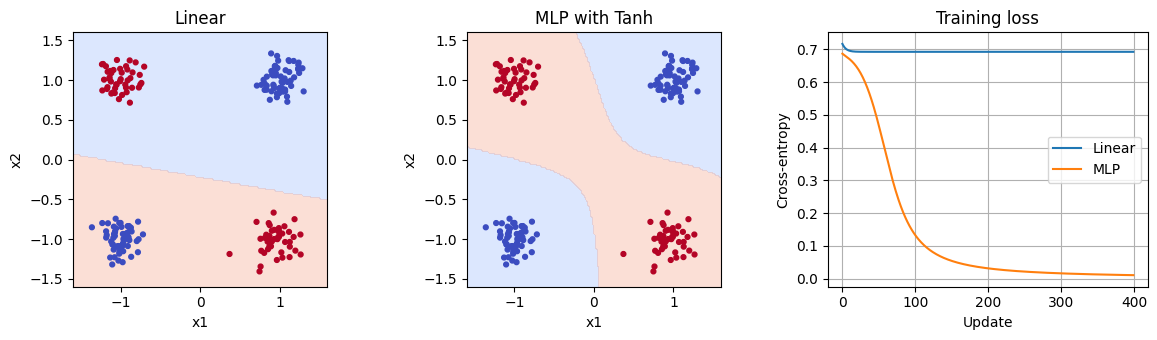

Autograd gradient:  0.00094200
Numerical gradient: 0.00094200
Absolute error: 1.36e-12


In [2]:
### CS231n_Lec04_Neural_Networks_and_Backpropagation


import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(4)
torch.set_num_threads(1)

HIDDEN = 8
EPOCHS = 400
LR = 0.2


## 1. XOR data: 0 if the two signs are the same, 1 if they are different
def make_data(n):
    bits = torch.randint(0, 2, (n, 2))
    # 0/1 → -1/+1
    # 2×0 - 1 = -1 ↔ 2×1 - 1 = 1
    centers = 2 * bits.float() - 1
    x = centers + 0.15 * torch.randn(n, 2)
    y = (bits[:, 0] != bits[:, 1]).long()
    return x, y

# Generate datasets for train & test and set a loss function
train_x, train_y = make_data(400)
test_x, test_y = make_data(200)
criterion = nn.CrossEntropyLoss()


# 2. Train two models with the same data
def train_model(use_hidden):
    torch.manual_seed(10)

    # hideen layers structure
    # Linear Classifier → Activation function → Linear Classifier
    if use_hidden:
        model = nn.Sequential(
            nn.Linear(2, HIDDEN),
            nn.Tanh(),
            nn.Linear(HIDDEN, 2),
        )
    else:
      # just one simple Linear Classifier
        model = nn.Linear(2, 2)

    # optimizer = SGD(Stochastic Gradient Descent)
    optimizer = torch.optim.SGD(model.parameters(), lr=LR)
    history = []

    for epoch in range(EPOCHS):
        scores = model(train_x)
        loss = criterion(scores, train_y)

        optimizer.zero_grad() # Reset (clear) previous gradients

        loss.backward() # Calculate the gradient for each parameter
                        # using the chain rule
        optimizer.step() # Update parameters using the calculated gradients
        history.append(loss.item())

    with torch.no_grad():
    # Disables gradient calculation to save memory and speed up inference.
        train_acc = (
            model(train_x).argmax(dim=1) == train_y
        ).float().mean().item()
        test_acc = (
            model(test_x).argmax(dim=1) == test_y
        ).float().mean().item()

    ## return → model, loss record(history), train accuracy, test accuracy
    return model, history, train_acc, test_acc

# Just Linear Classifier(Not using hidden layers)
linear, linear_loss, linear_train, linear_test = train_model(False)

# Multi-Layer Perceptron(using hidden layers)
mlp, mlp_loss, mlp_train, mlp_test = train_model(True)

# Compare two models' train & test accuracy
print(f"Linear | train={linear_train:.3f} | test={linear_test:.3f}")
print(f"MLP    | train={mlp_train:.3f} | test={mlp_test:.3f}")

with torch.no_grad():
    hidden = mlp[1](mlp[0](train_x))
    scores = mlp(train_x)

# Check the shape of Train dataset, Weights(1, 2), Hidden layers, and Scores
print("X:", tuple(train_x.shape))
print("W1:", tuple(mlp[0].weight.shape))
print("Hidden:", tuple(hidden.shape))
print("W2:", tuple(mlp[2].weight.shape))
print("Scores:", tuple(scores.shape))
assert scores.shape == (400, 2)


## 3. Make predictions across the entire coordinate plane
## to visualize decision regions
axis_values = np.linspace(-1.6, 1.6, 160)
xx, yy = np.meshgrid(axis_values, axis_values)
grid = torch.tensor(
    np.column_stack((xx.ravel(), yy.ravel())),
    dtype=torch.float32,
)

# Create a Figure and Subplots
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

# Visualization by model using a loop (first and second graphs)
for ax, name, model in zip(
    axes[:2], ("Linear", "MLP with Tanh"), (linear, mlp)
):
    # Calculate model predictions for the entire plane
    with torch.no_grad():
        region = model(grid).argmax(dim=1).numpy().reshape(xx.shape)

    # Draw the decision region (background color)
    ax.contourf(
        xx, yy, region,
        levels=[-0.5, 0.5, 1.5], cmap="coolwarm", alpha=0.3,
    )

    # Plot a scatter plot for test data (points)
    ax.scatter(
        test_x[:, 0].numpy(), test_x[:, 1].numpy(),
        c=test_y.numpy(), cmap="coolwarm",
        vmin=0, vmax=1, s=12,
    )

    # Set graph axes and styles
    ax.set_title(name)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_aspect("equal")

# Draw the graph of loss update with two models
axes[2].plot(linear_loss, label="Linear")
axes[2].plot(mlp_loss, label="MLP")
axes[2].set_title("Training loss")
axes[2].set_xlabel("Update")
axes[2].set_ylabel("Cross-entropy")
axes[2].legend()
axes[2].grid(True)
plt.tight_layout()
plt.show()


## 4. Check the gradient for a single initial weight
# Use float64 to reduce errors in numerical differentiation
mlp = mlp.double()
batch_x = train_x[:16].double()
batch_y = train_y[:16]

mlp.zero_grad()
criterion(mlp(batch_x), batch_y).backward()
weight = mlp[0].weight
autograd_value = weight.grad[0, 0].item()

original = weight[0, 0].item()
eps = 1e-5

with torch.no_grad():
    weight[0, 0] = original + eps
    loss_plus = criterion(mlp(batch_x), batch_y).item()
    weight[0, 0] = original - eps
    loss_minus = criterion(mlp(batch_x), batch_y).item()
    weight[0, 0] = original  # Restore original values

numerical_value = (loss_plus - loss_minus) / (2 * eps)
print(f"Autograd gradient:  {autograd_value:.8f}")
print(f"Numerical gradient: {numerical_value:.8f}")
print(f"Absolute error: {abs(autograd_value - numerical_value):.2e}")
assert abs(autograd_value - numerical_value) < 1e-6